How different were Tottenham performing during the 25/26 season?
- Differences between GW
- Outliers in performances?
- what were their problems? dispossion, passes forward?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
teamsCode = pd.read_csv("FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW1/teams.csv")
GW1 = pd.read_csv("FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW1/matches.csv")
GW2 = pd.read_csv("FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW2/matches.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW1/teams.csv'

In [ ]:
# Spurs 6
teamsCode[teamsCode['name'] == "Spurs"]

,code,id,name,short_name,strength,strength_overall_home,strength_overall_away,strength_attack_home,strength_attack_away,strength_defence_home,strength_defence_away,pulse_id,elo,fotmob_name
19,6,18,Spurs,TOT,3,1165,1175,1130,1150,1200,1200,21,1820,Tottenham Hotspur


In [ ]:
# GW1.columns
GW1[['home_team', 'away_team']]

,home_team,away_team
0,39.0,43.0
1,1.0,3.0
2,56.0,21.0
3,17.0,94.0
4,14.0,91.0
5,7.0,4.0
6,36.0,54.0
7,8.0,31.0
8,6.0,90.0
9,2.0,11.0


In [ ]:
GW1[(GW1['home_team'] == 6) | (GW1['away_team'] == 6)]

,gameweek,kickoff_time,home_team,home_team_elo,home_score,away_score,away_team,away_team_elo,finished,match_id,...,home_aerial_duels_won_pct,away_aerial_duels_won_pct,home_successful_dribbles,away_successful_dribbles,home_successful_dribbles_pct,away_successful_dribbles_pct,fotmob_id,stats_processed,player_stats_processed,tournament
8,1.0,2025-08-16T14:00:00+00:00,6.0,1774.01,3.0,0.0,90.0,1729.6,True,25-26-prem-tottenham-hotspur-vs-burnley,...,49.0,51.0,11.0,7.0,79.0,70.0,4813379.0,True,True,prem


In [ ]:
gws = []

In [ ]:
for i in range(1, 37):
  path = f"FPL-Core-Insights/data/2025-2026/By Tournament/Premier League/GW{i}/matches.csv"
  gws.append(pd.read_csv(path))

In [ ]:
tot = pd.concat(
    [gw[(gw['home_team'] == 6) | (gw['away_team'] == 6)] for gw in gws], ignore_index=True
)

In [ ]:
tot.head()

,gameweek,kickoff_time,home_team,home_team_elo,home_score,away_score,away_team,away_team_elo,finished,match_id,...,home_aerial_duels_won_pct,away_aerial_duels_won_pct,home_successful_dribbles,away_successful_dribbles,home_successful_dribbles_pct,away_successful_dribbles_pct,fotmob_id,stats_processed,player_stats_processed,tournament
0,1.0,2025-08-16T14:00:00+00:00,6.0,1774.01,3.0,0.0,90.0,1729.60,True,25-26-prem-tottenham-hotspur-vs-burnley,...,49.0,51.0,11.0,7.0,79.0,70.0,4813379.0,True,True,prem
1,2.0,2025-08-23T11:30:00+00:00,43.0,1967.75,0.0,2.0,6.0,1783.94,True,25-26-prem-manchester-city-vs-tottenham-hotspur,...,60.0,40.0,7.0,8.0,47.0,35.0,4813392.0,True,True,prem
2,3.0,2025-08-30T14:00:00+00:00,6.0,1802.91,0.0,1.0,91.0,1809.20,True,25-26-prem-tottenham-hotspur-vs-afc-bournemouth,...,52.0,48.0,10.0,8.0,37.0,50.0,4813403.0,True,True,prem
3,4.0,2025-09-13T16:30:00+00:00,21.0,1739.50,0.0,3.0,6.0,1793.89,True,25-26-prem-west-ham-united-vs-tottenham-hotspur,...,63.0,37.0,6.0,11.0,40.0,65.0,4813414.0,True,True,prem
4,5.0,2025-09-20T14:00:00+00:00,36.0,1818.08,2.0,2.0,6.0,1813.86,True,25-26-prem-brighton-hove-albion-vs-tottenham-h...,...,52.0,48.0,6.0,13.0,38.0,45.0,4813417.0,True,True,prem


In [ ]:
y_val = np.where(
    tot['home_team'] == 6,
    tot['home_xg_open_play'],
    np.where(
        tot['away_team'] == 6,
        tot['away_xg_open_play'],
        np.nan
    )
)

In [ ]:
x_val = np.array(range(1,37))

In [ ]:
stints = [
    (1, 25, "Thomas Frank", "#118AB2"),
    (26, 31, "Igor Tudor", "#9DE0AD"),
    (32, 36, "Roberto De Zerbi", "#547980")
]

In [ ]:
start_week = [start for start, end, name, color in stints][1:]
end_label = [name for start, end, name, color in stints][1:]
weeks = np.arange(1, 37)

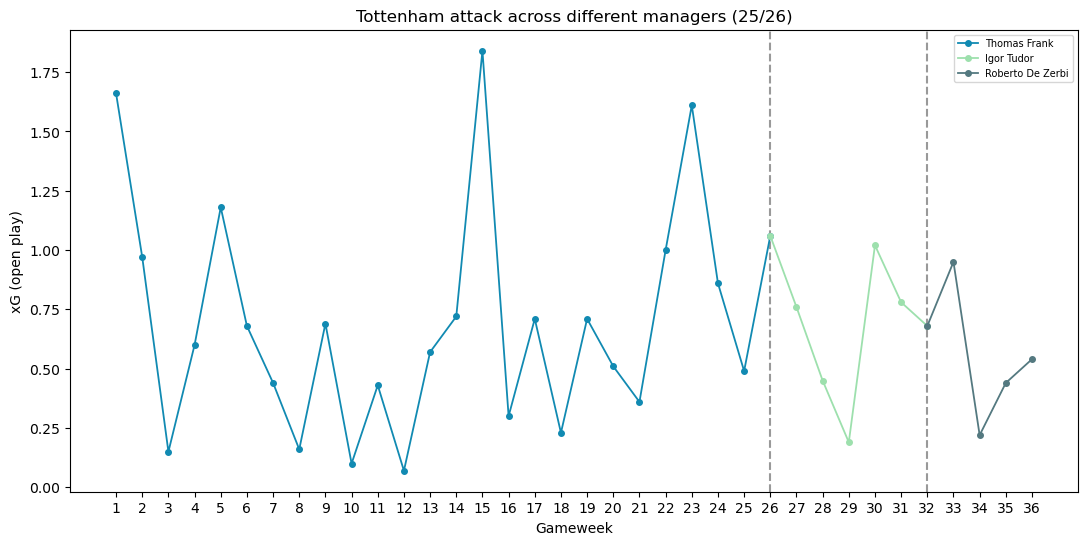

In [ ]:
plt.figure(figsize=(13,6))
for start, end, name, color in stints:
  seg = (weeks >= start) & (weeks <= end)
  idx = np.where(seg)[0]
  if idx[-1] + 1 < len(weeks):
        idx = np.append(idx, idx[-1] + 1)
  plt.plot(x_val[idx], y_val[idx], color=color, linewidth=1.3, zorder=3, marker='o',markersize = 4,linestyle="-", label=name)
plt.xlabel('Gameweek')
plt.ylabel('xG (open play)')
plt.xticks(range(1,37));
plt.title("Tottenham attack across different managers (25/26)")
for wk in start_week:
    plt.axvline(x=wk, color="gray", linestyle="--", linewidth=1.5, alpha=0.8, zorder=1)

plt.legend(loc="upper right", fontsize=7)